# 04 — Recomendación Semántica con `nomic-embed-text` (Ollama)

**Modelo local**: `nomic-embed-text` vía Ollama — vectores de **768 dimensiones**
**Por qué embeddings > TF-IDF**: TF-IDF compara palabras exactas. Un modelo de embeddings
entiende significado: "guerra naval" y "batalla marítima" tienen vectores cercanos
aunque no compartan tokens.

Pipeline:
1. Generar un embedding de 768 dims para cada libro (`description + genres`).
2. Guardar en caché (`src/data/embeddings_nomic.npy`) para no recomputar.
3. Búsqueda por similitud coseno → `recommend_semantic()`.
4. Comparación directa con el recomendador TF-IDF del notebook 03.

In [1]:
import os
import ast
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import ollama
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.feature_extraction.text import TfidfVectorizer
from tqdm.notebook import tqdm

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 120, "figure.figsize": (12, 5)})
sns.set_theme(style="whitegrid")

CSV_PATH      = os.path.join("..", "src", "data", "books_clean.csv")
EMBED_CACHE   = os.path.join("..", "src", "data", "embeddings_nomic.npy")
OLLAMA_MODEL  = "nomic-embed-text"

df = pd.read_csv(CSV_PATH)
df["genres"] = df["genres"].apply(
    lambda x: ast.literal_eval(x) if isinstance(x, str) and x.startswith("[") else []
)
df = df[df["has_ratings"].eq(True) & df["average_rating"].notna()].reset_index(drop=True)

df["text_corpus"] = (
    df["book_description"].fillna("") + " " +
    df["genres"].apply(lambda g: " ".join(g))
)

print(f"Libros cargados: {len(df):,}")
print(f"Modelo Ollama  : {OLLAMA_MODEL}")

# Verificar que Ollama está corriendo
try:
    test = ollama.embeddings(model=OLLAMA_MODEL, prompt="test")
    print(f"Embedding dim  : {len(test['embedding'])}")
except Exception as e:
    print(f"ERROR: Ollama no responde — {e}")
    print("Asegúrate de que Ollama está en ejecución: `ollama serve`")

Libros cargados: 4,406
Modelo Ollama  : nomic-embed-text


Embedding dim  : 768


## 1. Generación de embeddings

Los embeddings se guardan en `src/data/embeddings_nomic.npy`. Si el fichero ya existe,
se carga directamente sin llamar a Ollama.

In [2]:
def generate_embeddings(texts: list[str], model: str, cache_path: str) -> np.ndarray:
    """Genera o carga desde caché los embeddings de todos los textos."""
    if os.path.exists(cache_path):
        print(f"Cargando embeddings desde caché: {cache_path}")
        return np.load(cache_path)

    print(f"Generando {len(texts):,} embeddings con '{model}'...")
    print("(~3-5 min con CPU — se guardará en caché para futuros usos)")
    vectors = []
    t0 = time.time()

    for text in tqdm(texts, desc="Embeddings"):
        resp = ollama.embeddings(model=model, prompt=text[:2000])  # cap a 2000 chars
        vectors.append(resp["embedding"])

    matrix = np.array(vectors, dtype=np.float32)
    np.save(cache_path, matrix)

    elapsed = time.time() - t0
    print(f"Generados en {elapsed:.0f}s  |  Shape: {matrix.shape}")
    print(f"Guardado en: {cache_path}")
    return matrix


embed_matrix = generate_embeddings(df["text_corpus"].tolist(), OLLAMA_MODEL, EMBED_CACHE)
print(f"\nMatriz de embeddings: {embed_matrix.shape}  (libros × dimensiones)")

Generando 4,406 embeddings con 'nomic-embed-text'...
(~3-5 min con CPU — se guardará en caché para futuros usos)


Embeddings:   0%|          | 0/4406 [00:00<?, ?it/s]

Generados en 214s  |  Shape: (4406, 768)
Guardado en: ../src/data/embeddings_nomic.npy

Matriz de embeddings: (4406, 768)  (libros × dimensiones)


## 2. Sistema de recomendación semántica

In [3]:
def recommend_semantic(book_title: str, n: int = 5, query_text: str = None) -> pd.DataFrame:
    """Recomendación basada en embeddings de nomic-embed-text.

    Parámetros
    ----------
    book_title  : Título exacto (case-insensitive). Si no está en el corpus usa query_text.
    n           : Número de recomendaciones.
    query_text  : Texto libre para cold-start (descripción del libro externo).
    """
    mask = df["book_title"].str.lower() == book_title.lower()

    if mask.any():
        idx       = df[mask].index[0]
        query_vec = embed_matrix[idx].reshape(1, -1)
        exclude   = {idx}
    elif query_text:
        print(f"[cold-start] '{book_title}' no está en el corpus — generando embedding...")
        resp      = ollama.embeddings(model=OLLAMA_MODEL, prompt=query_text[:2000])
        query_vec = np.array(resp["embedding"], dtype=np.float32).reshape(1, -1)
        exclude   = set()
    else:
        raise ValueError(f"'{book_title}' no encontrado. Proporciona query_text para cold-start.")

    scores  = cosine_similarity(query_vec, embed_matrix).flatten()
    top_idx = [i for i in scores.argsort()[::-1] if i not in exclude][:n]

    result = df.iloc[top_idx][["book_title", "author", "average_rating", "genres"]].copy()
    result.insert(0, "similarity", scores[top_idx].round(4))
    return result.reset_index(drop=True)

## 3. Pruebas — comparativa semántica vs TF-IDF

### Caso a) *Dead Wake* (Erik Larson) — en el corpus

In [4]:
# ── TF-IDF (referencia del notebook 03) ─────────────────────
tfidf_vec = TfidfVectorizer(max_features=8000, stop_words="english",
                             ngram_range=(1,2), min_df=2, sublinear_tf=True)
tfidf_matrix = tfidf_vec.fit_transform(df["text_corpus"])

def recommend_tfidf(book_title, n=5, query_text=None):
    mask = df["book_title"].str.lower() == book_title.lower()
    if mask.any():
        idx = df[mask].index[0]; query_vec = tfidf_matrix[idx]; exclude = {idx}
    elif query_text:
        query_vec = tfidf_vec.transform([query_text]); exclude = set()
    else:
        raise ValueError(f"'{book_title}' no encontrado.")
    scores  = cosine_similarity(query_vec, tfidf_matrix).flatten()
    top_idx = [i for i in scores.argsort()[::-1] if i not in exclude][:n]
    result  = df.iloc[top_idx][["book_title", "author", "average_rating"]].copy()
    result.insert(0, "similarity", scores[top_idx].round(4))
    return result.reset_index(drop=True)

BOOK_A = "Dead Wake: The Last Crossing of the Lusitania"

print("=== TF-IDF ===")
print(recommend_tfidf(BOOK_A)[["similarity","book_title","author"]].to_string(index=False))
print()
print("=== Semántico (nomic-embed-text) ===")
print(recommend_semantic(BOOK_A)[["similarity","book_title","author"]].to_string(index=False))

=== TF-IDF ===
 similarity                                                                                  book_title        author
     0.2402                               Lusitania: Triumph, Tragedy, and the End of the Edwardian Age     Greg King
     0.1770                                                 Wilful Murder: The Sinking of the Lusitania Diana Preston
     0.1494                                           The Wager: A Tale of Shipwreck, Mutiny and Murder   David Grann
     0.1398 The Demon of Unrest: A Saga of Hubris, Heartbreak, and Heroism at the Dawn of the Civil War   Erik Larson
     0.1361       The Splendid and the Vile: A Saga of Churchill, Family, and Defiance During the Blitz   Erik Larson

=== Semántico (nomic-embed-text) ===
 similarity                                                                                  book_title             author
     0.9150                                           The Wager: A Tale of Shipwreck, Mutiny and Murder        David

### Caso b) Cold-start — *Fourth Wing* de Rebecca Yarros

In [5]:
FOURTH_WING_TEXT = (
    "Violet Sorrengail is ordered to join the riders quadrant and attempt to bond a dragon "
    "at Basgiath War College. The dragons are terrifying and unpredictable. War is coming "
    "and the stakes are high in this romantic fantasy epic set in a world of war, dragons, "
    "and dangerous secrets. A young woman must survive elite military training and navigate "
    "deadly political intrigue while powerful forces seek to destroy her."
)

print("=== TF-IDF — Fourth Wing ===")
print(recommend_tfidf("Fourth Wing", n=5, query_text=FOURTH_WING_TEXT)[["similarity","book_title","author"]].to_string(index=False))
print()
print("=== Semántico — Fourth Wing ===")
print(recommend_semantic("Fourth Wing", n=5, query_text=FOURTH_WING_TEXT)[["similarity","book_title","author"]].to_string(index=False))

=== TF-IDF — Fourth Wing ===
 similarity                                                                    book_title                 author
     0.1697                      Kelisa's Adventures: Book 1: The Road to Castle Wyegates         Karen L.  West
     0.1583                                                                       Arising Lisa Perskie Rodriguez
     0.1418                                                       Orange Is the New Black           Piper Kerman
     0.1167                                                          Whip Smart: A Memoir          Melissa Febos
     0.1151 Shadows In The Jungle: The Alamo Scouts Behind Japanese Lines In World War II        Larry Alexander

=== Semántico — Fourth Wing ===
[cold-start] 'Fourth Wing' no está en el corpus — generando embedding...
 similarity                       book_title                 author
     0.7623                          Arising Lisa Perskie Rodriguez
     0.7374      The Shifters of Yellowstone       

### Caso c) Cold-start — *Frankenstein* de Mary Shelley

In [6]:
FRANKENSTEIN_TEXT = (
    "Victor Frankenstein, a brilliant scientist, becomes obsessed with creating life. "
    "He assembles a creature from dead body parts and animates it with electricity. "
    "The creature, intelligent but hideous, is abandoned by his creator and rejected by humanity. "
    "Seeking revenge, he pursues Frankenstein across Europe. A gothic horror novel exploring "
    "themes of ambition, responsibility, and what it means to be human."
)

print("=== TF-IDF — Frankenstein ===")
print(recommend_tfidf("Frankenstein", n=5, query_text=FRANKENSTEIN_TEXT)[["similarity","book_title","author"]].to_string(index=False))
print()
print("=== Semántico — Frankenstein ===")
print(recommend_semantic("Frankenstein", n=5, query_text=FRANKENSTEIN_TEXT)[["similarity","book_title","author"]].to_string(index=False))

=== TF-IDF — Frankenstein ===
 similarity                                                                                                book_title                 author
     0.1358                                     The Strange Case of Dr. Jekyll and Mr. Hyde and Other Tales of Terror Robert Louis Stevenson
     0.1004                                                                              Gothic Art: Glorious Visions        Michael Camille
     0.0959                                                                   The Walking Dead, Vol. 1: Days Gone Bye         Robert Kirkman
     0.0903 Among the Dead Cities: The History and Moral Legacy of the WWII Bombing of Civilians in Germany and Japan          A.C. Grayling
     0.0903                         A Woman Named Jackie: An Intimate Biography of Jacqueline Bouvier Kennedy Onassis       C. David Heymann

=== Semántico — Frankenstein ===
[cold-start] 'Frankenstein' no está en el corpus — generando embedding...
 similarity     

### Caso d) Cold-start — *Antigone* de Sófocles

In [7]:
ANTIGONE_TEXT = (
    "Antigone, daughter of Oedipus, defies the decree of King Creon of Thebes and attempts "
    "to bury her slain brother Polynices. Creon condemns her to death for disobeying state law. "
    "The tragedy explores the conflict between divine law and human authority, loyalty to family "
    "versus duty to the state, and the consequences of pride and hubris in ancient Greece."
)

print("=== TF-IDF — Antigone ===")
print(recommend_tfidf("Antigone", n=5, query_text=ANTIGONE_TEXT)[["similarity","book_title","author"]].to_string(index=False))
print()
print("=== Semántico — Antigone ===")
print(recommend_semantic("Antigone", n=5, query_text=ANTIGONE_TEXT)[["similarity","book_title","author"]].to_string(index=False))

=== TF-IDF — Antigone ===
 similarity                                                                                            book_title           author
     0.1890 The Spartans: The World of the Warrior - Heroes of Ancient Greece, From Utopia to Crisis and Collapse   Paul Cartledge
     0.1590                                             Ancient Greece: A Political, Social, and Cultural History Sarah B. Pomeroy
     0.1562                                                                                    The Life of Greece      Will Durant
     0.1521                                                   The Cambridge Illustrated History of Ancient Greece   Paul Cartledge
     0.1392                                         Historical and Theological Foundations of Law: Ancient Wisdom     John Eidsmoe

=== Semántico — Antigone ===


[cold-start] 'Antigone' no está en el corpus — generando embedding...


 similarity                                                                 book_title             author
     0.7424                                                Murder of a Medici Princess Caroline P. Murphy
     0.7287 Ungrateful Daughters: The Stuart Princesses Who Stole Their Father's Crown    Maureen  Waller
     0.7275                                                      Hypatia of Alexandria           Dzielska
     0.7241                                                             Becoming Queen      Kate Williams
     0.7222            Catherine of Aragon: An Intimate Life of Henry VIII's True Wife        Amy Licence


## 4. Distribución de similitudes

¿Cómo de "parecidos" son los libros del corpus entre sí según el modelo semántico?

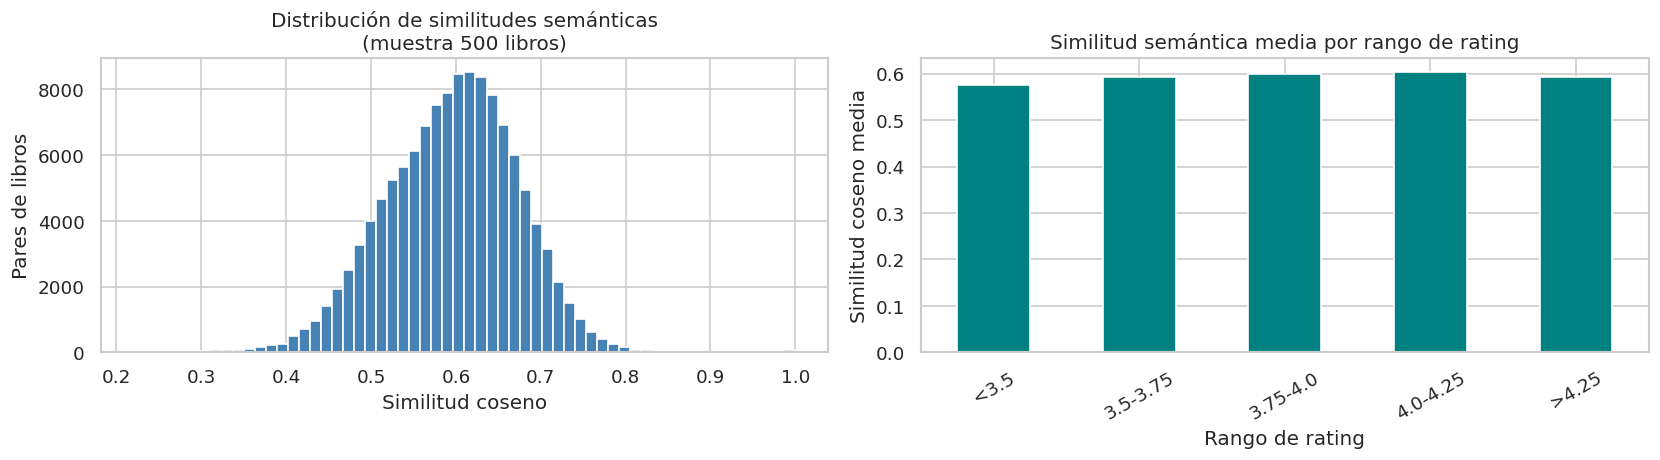

In [8]:
# Muestra aleatoria de 500 libros para no calcular toda la matriz (4406×4406)
rng  = np.random.default_rng(42)
idx  = rng.choice(len(df), size=500, replace=False)
sims = cosine_similarity(embed_matrix[idx])

# Triángulo superior (excluir diagonal)
upper = sims[np.triu_indices_from(sims, k=1)]

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].hist(upper, bins=60, color="steelblue", edgecolor="white")
axes[0].set(title="Distribución de similitudes semánticas\n(muestra 500 libros)",
            xlabel="Similitud coseno", ylabel="Pares de libros")

# Comparativa: media de similitud por rango de rating
sims_all = cosine_similarity(embed_matrix).mean(axis=1)
df_plot  = df.copy()
df_plot["mean_similarity"] = sims_all
df_plot["rating_bin"] = pd.cut(df_plot["average_rating"],
                               bins=[0, 3.5, 3.75, 4.0, 4.25, 5.0],
                               labels=["<3.5","3.5-3.75","3.75-4.0","4.0-4.25",">4.25"])

df_plot.groupby("rating_bin", observed=True)["mean_similarity"].mean().plot(
    kind="bar", ax=axes[1], color="teal", edgecolor="white"
)
axes[1].set(title="Similitud semántica media por rango de rating",
            xlabel="Rango de rating", ylabel="Similitud coseno media")
axes[1].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

## 5. Conclusiones

| | TF-IDF | `nomic-embed-text` |
|--|--------|-------------------|
| **Velocidad** | Instantáneo | ~3-5 min (solo la primera vez) |
| **Similitud léxica** | Excelente | Buena |
| **Similitud semántica** | Limitada | Excelente |
| **Cold-start** | Depende del vocabulario | Entiende el significado |
| **Tamaño modelo** | ~MB en RAM | 274 MB en disco |

**Recomendación para la editorial**: usar `nomic-embed-text` como motor principal
de recomendación. TF-IDF puede mantenerse como fallback rápido si Ollama no está disponible.
El caché de embeddings (`embeddings_nomic.npy`) solo hay que regenerarlo cuando se añaden
libros nuevos al corpus.